# Troposphere that follows the terrain

**Frame F39362 (Canberra and the Southern Tablelands, Australia), 2016-07
to 2025-04, 247 granules (stakeholder run, product version 0.10).**

Radar delay through the lower atmosphere depends on how much air the
signal crosses, so it changes with elevation, and the vertical profile
changes with season and weather. On a frame with relief, that stratified
delay correlates displacement with topography. Little deforms here, so
whatever correlates with elevation is atmosphere. The question is where it
matters: in single epochs, in velocities, or both.

The window runs from Canberra (about 600 m) up into the Brindabella Range
(about 1900 m). Elevation comes from the Copernicus GLO-30 DEM, read from
its public bucket.

This notebook ran on real granules; its outputs are saved, and the
documentation build does not run it again.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rioxarray
import xarray as xr
from pyproj import Transformer
from rioxarray.merge import merge_arrays

import disp_xr as dxr

warnings.simplefilter("ignore", FutureWarning)
os.environ["TQDM_DISABLE"] = "1"  # GNSS download progress bars
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="invalid value encountered in divide")
frame = Path("/u/aurora-r0/govorcin/01_OPERA/STAKEHOLDER/AUSTRALIA/Canberra/ncs")


def title(ax, text):
    """Title the panel on the left, without xarray's automatic title."""
    ax.set_title("")
    ax.set_title(text, loc="left")


raw = dxr.open_disp(frame, layers=["displacement", "recommended_mask"])
west, south, east, north = 148.75, -35.55, 149.25, -35.15
to_grid = Transformer.from_crs("EPSG:4326", raw.rio.crs, always_xy=True)
(x0, x1), (y0, y1) = to_grid.transform([west, east], [south, north])
window = raw.sel(x=slice(x0, x1), y=slice(y1, y0))
print(f"{len(raw.attrs['input_granules'])} granules; window {dict(window.sizes)}")

247 granules; window {'time': 247, 'y': 1448, 'x': 1545}


## Elevation on the DISP grid

Two 1-degree GLO-30 tiles cover the window. They are read over HTTPS
(only the window's blocks), merged and resampled onto the DISP grid.

In [2]:
url = (
    "https://copernicus-dem-30m.s3.amazonaws.com/"
    "Copernicus_DSM_COG_10_S36_00_E{lon}_00_DEM/Copernicus_DSM_COG_10_S36_00_E{lon}_00_DEM.tif"
)
tiles = [
    rioxarray.open_rasterio(url.format(lon=lon), masked=True)
    .squeeze("band", drop=True)
    .rio.clip_box(west - 0.01, south - 0.01, east + 0.01, north + 0.01)
    for lon in (148, 149)
]
template = window.displacement.isel(time=0, drop=True)
dem = (
    merge_arrays(tiles).rio.reproject_match(template, nodata=np.nan).rename("elevation")
)
dem = dem.assign_coords(x=window.x, y=window.y)  # same grid, exact labels
dem = dem.where(dem > 0)  # merge fills gaps with 0; the window is all inland
print(f"elevation {float(dem.min()):.0f} to {float(dem.max()):.0f} m")

elevation 400 to 1766 m


## Chain and reference

Mask, chain, and reference to a 1 km box at the GNSS station nearest the
window center.

In [3]:
gps = dxr.gnss.load(window)
center_x, center_y = float(window.x.mean()), float(window.y.mean())
nearest = int(np.hypot(gps.x - center_x, gps.y - center_y).argmin())
station = str(gps.station.values[nearest])
lon, lat = float(gps.lon[nearest]), float(gps.lat[nearest])
ds = dxr.stack_disp(dxr.mask(window, "recommended"))
ds = dxr.rereference(
    ds, "area", bbox=(lon - 0.005, lat - 0.005, lon + 0.005, lat + 0.005)
)
ref_elevation = float(
    dem.sel(x=float(gps.x[nearest]), y=float(gps.y[nearest]), method="nearest")
)
print(f"reference: {station}, {ref_elevation:.0f} m")
displacement = (1e3 * ds.displacement).persist()  # mm, read once

reference: STR2, 781 m


## A slope for every epoch

For each epoch, the least-squares slope of displacement against elevation
over the valid pixels: how many millimeters the scene moves per kilometer
of height, relative to the first epoch. Every epoch is a full map, so this
is one reduction over `y` and `x`.

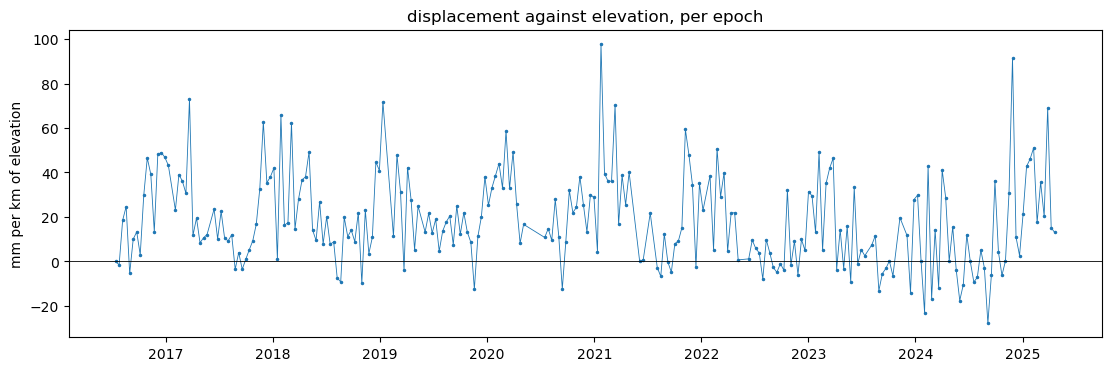

median slope by month (mm/km): 1: +32, 2: +36, 3: +33, 4: +22, 5: +11, 6: +10, 7: +7, 8: +10, 9: +0, 10: +9, 11: +20, 12: +29


In [4]:
height = (dem - ref_elevation) / 1e3  # km above the reference
valid = displacement.notnull() & height.notnull()
h = height.where(valid)
d = displacement.where(valid)
slope = (
    ((h - h.mean(("y", "x"))) * (d - d.mean(("y", "x")))).sum(("y", "x"))
    / ((h - h.mean(("y", "x"))) ** 2).sum(("y", "x"))
).compute()

fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
ax.plot(slope.time, slope, ".-", ms=3, lw=0.6)
ax.axhline(0, color="k", lw=0.6)
ax.set(
    ylabel="mm per km of elevation", title="displacement against elevation, per epoch"
)
plt.show()
month = slope.groupby("time.month").median()
print(
    "median slope by month (mm/km): "
    + ", ".join(f"{m}: {v:+.0f}" for m, v in zip(month.month.values, month.values))
)

The slope follows the seasons. The first epoch (July, winter) is the
zero; summer epochs (December to March) sit 30 to 35 mm/km above it, and
single epochs reach 90. Over the 1000 m between the reference and the
ridges that is several centimeters of apparent motion.

## Removing it

The simplest correction subtracts, at each epoch, the slope times the
height above the reference. It keeps the reference at zero. On a quiet
frame that is safe; where deformation itself follows the terrain
(volcanoes, mountain-front faults) it would remove signal too, and a
weather-model correction is the better choice.

The correction scales with height above the reference, so it changes
little in the valleys and most on the ridges.

as delivered: median scatter of a series below 900 m 7.2 mm, above 1300 m 14.7 mm


terrain term removed: median scatter of a series below 900 m 7.5 mm, above 1300 m 8.2 mm


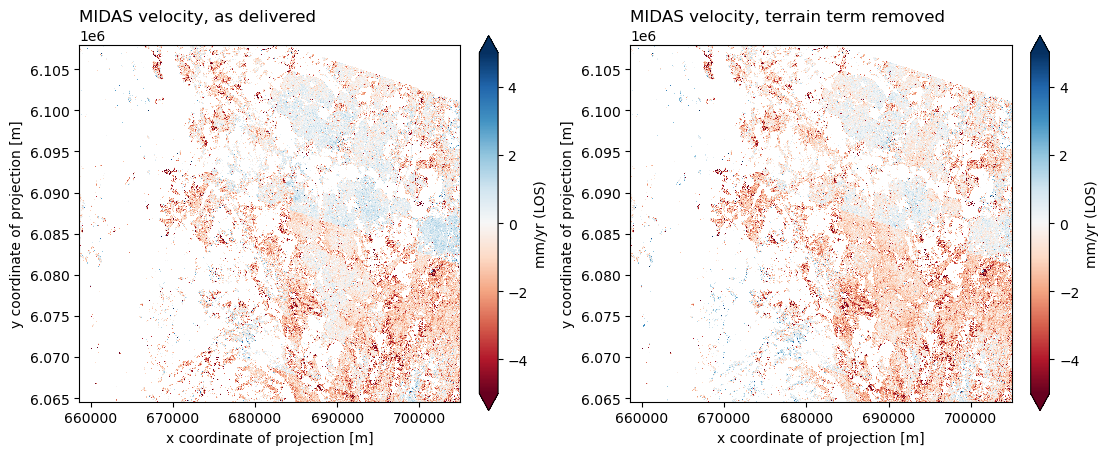

In [5]:
corrected = displacement - slope * height
# Pixels valid in fewer than half the epochs are left out, here and below.
enough = displacement.isel(time=slice(1, None)).notnull().mean("time").compute() >= 0.5
bands = {"below 900 m": enough & (dem < 900), "above 1300 m": enough & (dem > 1300)}
for name, series in [
    ("as delivered", displacement),
    ("terrain term removed", corrected),
]:
    spread = series.std("time").compute()
    print(
        f"{name}: median scatter of a series "
        + ", ".join(
            f"{band} {float(spread.where(inside).median()):.1f} mm"
            for band, inside in bands.items()
        )
    )
fits = {
    name: (
        dxr.fit_velocity(
            ds.assign(displacement=(series / 1e3).assign_attrs(ds.displacement.attrs)),
            method="midas",
        ).velocity.compute()
        * 1e3
    )
    for name, series in [
        ("as delivered", displacement),
        ("terrain term removed", corrected),
    ]
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
for ax, (name, vel) in zip(axes, fits.items()):
    vel.where(enough).plot.imshow(
        ax=ax, cmap="RdBu", vmin=-5, vmax=5, cbar_kwargs={"label": "mm/yr (LOS)"}
    )
    ax.set_aspect("equal")
    title(ax, f"MIDAS velocity, {name}")
plt.show()

## Velocity against elevation

A seasonal delay can leak into a velocity through gaps and the start and
end dates. Here it leaves a small trend with height, about a millimeter
per year per kilometer, and removing the terrain term shrinks it. The
highest bins hold few pixels and scatter the most. With nine years of
12-day sampling, the stratified delay matters far more for single epochs
and short series than for the velocity.

as delivered: velocity spread (std) 1.3 mm/yr


terrain term removed: velocity spread (std) 1.3 mm/yr


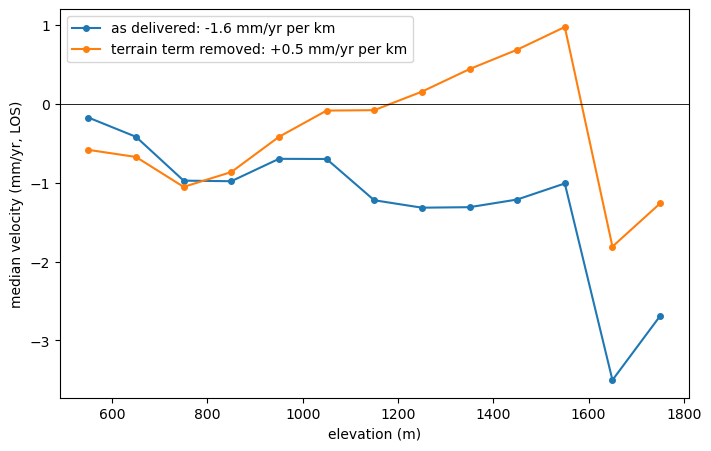

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.4), layout="constrained")
for name, vel in fits.items():
    v = vel.where(enough)
    binned = (
        v.assign_coords(h=dem).groupby_bins("h", np.arange(500, 2001, 100)).median()
    )
    pairs = xr.Dataset({"km": dem / 1e3, "v": v}).to_dataframe()[["km", "v"]]
    pairs = pairs.dropna().astype("float64")
    trend = np.polyfit(pairs.km, pairs.v, 1)[0]
    centers = [b.mid for b in binned.h_bins.values]
    ax.plot(centers, binned, "o-", ms=4, label=f"{name}: {trend:+.1f} mm/yr per km")
    print(f"{name}: velocity spread (std) {float(v.std()):.1f} mm/yr")
ax.axhline(0, color="k", lw=0.6)
ax.set(xlabel="elevation (m)", ylabel="median velocity (mm/yr, LOS)")
ax.legend()
plt.show()

## One pixel on the range

A pixel high in the Brindabellas, as delivered and with the terrain term
removed.

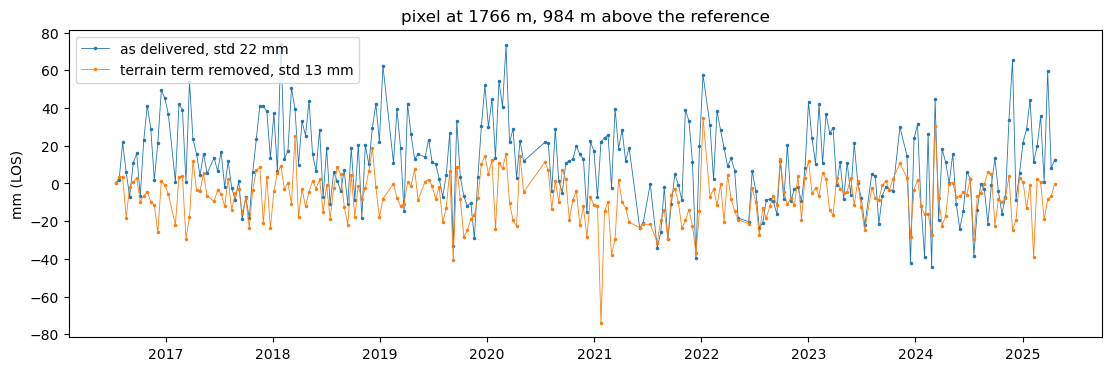

In [7]:
high = dem.where(enough).where(dem > dem.quantile(0.98)).argmax(("y", "x"))
pixel = {k: int(v) for k, v in high.items()}
fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
for name, series in [
    ("as delivered", displacement),
    ("terrain term removed", corrected),
]:
    one = series.isel(pixel).compute()
    ax.plot(
        one.time,
        one,
        ".-",
        ms=3,
        lw=0.6,
        label=f"{name}, std {float(one.std()):.0f} mm",
    )
above = float(dem.isel(pixel)) - ref_elevation
ax.set(
    ylabel="mm (LOS)",
    title=f"pixel at {float(dem.isel(pixel)):.0f} m, {above:.0f} m above the reference",
)
ax.legend(loc="upper left")
plt.show()